# Time-Series Regression for Predicting Rack Inlet Temperature in a Free-Cooled Data Center

## EDA

In [2]:
# ============================================================
# FULL DATA INGEST + EDA (ALL CONTROLLED SETPOINTS)
# Resolution: 30 MINUTES
#
# Purpose:
#   - Load ALL CSV files from controlled/<setpoint>/ folders
#   - Automatically detect sensor groups
#   - Build a unified WIDE dataset (30-min)
#   - Create a compact KEY VIEW
#   - Produce clean, report-ready EDA visualisations
#
# OUTPUT (output/section2/):
#   - file_overview.csv
#   - setpoint_summary.csv
#   - wide_30min_controlled_all.csv
#   - key_view_30min_controlled_all.csv
#   - plots/*.png
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 0) CONFIG
# ----------------------------
BASE_DIR = Path("data")
CONTROLLED_DIR = BASE_DIR / "controlled"

RESAMPLE_RULE = "30T"
GROUP_COL = "supply_setpoint_label"

OUT_DIR = Path("output/section2")
PLOT_DIR = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 180)

# ----------------------------
# 1) HELPERS
# ----------------------------
def find_time_col(df):
    candidates = [c for c in df.columns if re.search(r"(time|timestamp|date)", c, re.I)]
    return candidates[0] if candidates else df.columns[0]

def read_csv_ts(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    tcol = find_time_col(df)
    df[tcol] = pd.to_datetime(df[tcol], errors="coerce")
    df = df.dropna(subset=[tcol]).copy()
    for c in df.columns:
        if c != tcol:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.set_index(tcol).sort_index()
    df = df[~df.index.duplicated(keep="first")]
    return df

def resample(df: pd.DataFrame) -> pd.DataFrame:
    out = df.resample(RESAMPLE_RULE).mean()
    return out.dropna(how="all")

def prefix(df: pd.DataFrame, name: str) -> pd.DataFrame:
    df = df.copy()
    df.columns = [f"{name}__{c}" for c in df.columns]
    return df

def file_overview(folder: Path) -> pd.DataFrame:
    rows = []
    for f in sorted(folder.glob("*.csv")):
        try:
            d = pd.read_csv(f)
            rows.append({
                "setpoint": folder.name,
                "file": f.name,
                "rows": d.shape[0],
                "cols": d.shape[1],
                "missing_%": float(d.isna().mean().mean() * 100),
            })
        except Exception as e:
            rows.append({
                "setpoint": folder.name,
                "file": f.name,
                "rows": np.nan,
                "cols": np.nan,
                "missing_%": np.nan,
                "error": str(e)[:120],
            })
    return pd.DataFrame(rows)

def build_wide(folder: Path) -> pd.DataFrame:
    parts = []
    for f in sorted(folder.glob("*.csv")):
        df = read_csv_ts(f)
        df = resample(df)
        df = prefix(df, f.stem)
        parts.append(df)
    if not parts:
        raise RuntimeError(f"No CSVs in {folder}")
    wide = parts[0]
    for p in parts[1:]:
        wide = wide.join(p, how="outer")
    return wide.sort_index()

def all_matches(cols, patterns):
    out = []
    for p in patterns:
        out.extend([c for c in cols if re.search(p, c, re.I)])
    return sorted(set(out))

def first_match(cols, patterns):
    for p in patterns:
        hits = [c for c in cols if re.search(p, c, re.I)]
        if hits:
            return hits[0]
    return None

def save_fig(name):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.close()

# ----------------------------
# 2) DISCOVER CONTROLLED SETPOINTS
# ----------------------------
folders = sorted(
    [p for p in CONTROLLED_DIR.iterdir() if p.is_dir() and p.name.isdigit()],
    key=lambda p: int(p.name)
)
setpoints = [int(p.name) for p in folders]
print("Detected controlled setpoints:", setpoints)

# ----------------------------
# 3) FILE OVERVIEW
# ----------------------------
overview = pd.concat([file_overview(p) for p in folders], ignore_index=True)
overview.to_csv(OUT_DIR / "file_overview.csv", index=False)
display(overview)

summary = (
    overview.groupby("setpoint")
    .agg(files=("file", "count"),
         min_rows=("rows", "min"),
         max_rows=("rows", "max"),
         avg_missing=("missing_%", "mean"))
    .reset_index()
)
summary.to_csv(OUT_DIR / "setpoint_summary.csv", index=False)
display(summary)

# ----------------------------
# 4) BUILD COMBINED WIDE DATASET (30-MIN)
# ----------------------------
wide_parts = []
for p in folders:
    sp = int(p.name)
    w = build_wide(p)
    w[GROUP_COL] = sp
    wide_parts.append(w)
    print(f"Built setpoint {sp}: {w.shape}")

wide_all = pd.concat(wide_parts, axis=0).sort_index()
print("Combined wide shape:", wide_all.shape)

wide_all.to_csv(OUT_DIR / "wide_30min_controlled_all.csv")

# ----------------------------
# 5) AUTO-DETECT SENSOR GROUPS
# ----------------------------
groups = {
    "Temp_Control":    all_matches(wide_all.columns, [r"^Temp_Control__"]),
    "Temp_Cold_Rack":  all_matches(wide_all.columns, [r"^Temp_Cold_Rack_"]),
    "Temp_Hot_Rack":   all_matches(wide_all.columns, [r"^Temp_Hot_Rack_"]),
    "RH_Cold_Rack":    all_matches(wide_all.columns, [r"^RH_Cold_Rack_"]),
    "RH_Hot_Rack":     all_matches(wide_all.columns, [r"^RH_Hot_Rack_"]),
    "DP_Rack":         all_matches(wide_all.columns, [r"^DP_Rack_"]),
    "AirFlow":         all_matches(wide_all.columns, [r"^AirFlow_Control__"]),
    "Energy_AirCon":   all_matches(wide_all.columns, [r"^Energy_AirCon__"]),
    "Energy_Fan":      all_matches(wide_all.columns, [r"^Energy_Fan__", r"^Energy_Fans__"]),
    "Energy_Rack":     all_matches(wide_all.columns, [r"^Energy_Rack__"]),
    "Outside":         all_matches(wide_all.columns, [r"^Outside_Temp_RH__"]),
    "Room":            all_matches(wide_all.columns, [r"^Room_Temp_RH__"]),
}

display(pd.DataFrame(
    [{"group": k, "n_cols": len(v)} for k, v in groups.items()]
).sort_values("n_cols", ascending=False))

# ----------------------------
# 6) BUILD KEY VIEW (COMPACT, INTERPRETABLE)
# ----------------------------
key = pd.DataFrame(index=wide_all.index)
key[GROUP_COL] = wide_all[GROUP_COL]

# Supply setpoint
sp_col = first_match(groups["Temp_Control"], [r"setpoint|sp|supply"])
if sp_col:
    key["supply_temp_setpoint_meas"] = wide_all[sp_col]

# Outdoor
ot = first_match(groups["Outside"], [r"temp"])
orh = first_match(groups["Outside"], [r"rh|humid"])
if ot: key["outdoor_temp"] = wide_all[ot]
if orh: key["outdoor_rh"] = wide_all[orh]

# Energy
cp = first_match(groups["Energy_AirCon"], [r"power|kw"])
fp = first_match(groups["Energy_Fan"], [r"power|kw"])
ip = first_match(groups["Energy_Rack"], [r"power|kw"])
if cp: key["cooling_power"] = wide_all[cp]
if fp: key["fan_power"] = wide_all[fp]
if ip: key["it_power"] = wide_all[ip]

# Airflow & pressure
af = first_match(groups["AirFlow"], [r"flow|rate"])
dp = first_match(groups["DP_Rack"], [r"dp|press"])
if af: key["airflow_rate"] = wide_all[af]
if dp: key["dp_rack"] = wide_all[dp]

# Rack temperatures
if groups["Temp_Cold_Rack"]:
    key["cold_rack_temp_avg"] = wide_all[groups["Temp_Cold_Rack"]].mean(axis=1)
if groups["Temp_Hot_Rack"]:
    key["hot_rack_temp_avg"] = wide_all[groups["Temp_Hot_Rack"]].mean(axis=1)
if "cold_rack_temp_avg" in key and "hot_rack_temp_avg" in key:
    key["delta_t"] = key["hot_rack_temp_avg"] - key["cold_rack_temp_avg"]

# Rack RH (optional)
if groups["RH_Cold_Rack"]:
    key["cold_rack_rh_avg"] = wide_all[groups["RH_Cold_Rack"]].mean(axis=1)
if groups["RH_Hot_Rack"]:
    key["hot_rack_rh_avg"] = wide_all[groups["RH_Hot_Rack"]].mean(axis=1)

key.to_csv(OUT_DIR / "key_view_30min_controlled_all.csv")
display(key.describe().T)

# ----------------------------
# 7) EDA VISUALISATIONS (REPORT-READY)
# ----------------------------

# 7.1 Distributions
for v in key.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(6, 4))
    plt.hist(key[v].dropna(), bins=35)
    plt.title(f"Distribution: {v}")
    plt.xlabel(v)
    plt.ylabel("Count")
    save_fig(f"hist_{v}")

# 7.2 Boxplots by setpoint
box_vars = ["cold_rack_temp_avg", "delta_t", "outdoor_temp", "it_power"]
for v in box_vars:
    if v not in key.columns:
        continue
    data, labels = [], []
    for sp in setpoints:
        d = key[key[GROUP_COL] == sp][v].dropna()
        if len(d) > 10:
            data.append(d.values)
            labels.append(str(sp))
    if len(data) >= 2:
        plt.figure(figsize=(12, 4))
        plt.boxplot(data, tick_labels=labels)
        plt.title(f"{v} by setpoint")
        plt.xlabel("Setpoint (°C)")
        plt.ylabel(v)
        save_fig(f"box_{v}_by_setpoint")

# 7.3 Correlation heatmap
num = key.drop(columns=[GROUP_COL], errors="ignore").select_dtypes(include=np.number)
corr = num.corr(method="spearman")
plt.figure(figsize=(9, 7))
plt.imshow(corr.values)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.colorbar(label="Spearman ρ")
plt.title("Spearman correlation (key variables)")
save_fig("corr_spearman_key")

# 7.4 Time series (per setpoint, no fake continuity)
def robust_ylim(s):
    if s.dropna().empty:
        return None
    lo, hi = np.percentile(s.dropna(), [1, 99])
    pad = (hi - lo) * 0.05
    return lo - pad, hi + pad

ts_vars = ["cold_rack_temp_avg", "delta_t", "outdoor_temp", "it_power"]
ylims = {v: robust_ylim(key[v]) for v in ts_vars if v in key}

for sp in setpoints:
    d = key[key[GROUP_COL] == sp]
    for v in ts_vars:
        if v not in d:
            continue
        plt.figure(figsize=(10, 3))
        plt.plot(d.index, d[v])
        plt.title(f"{v} over time (30-min) — setpoint {sp}°C")
        plt.xlabel("Time")
        plt.ylabel(v)
        if v in ylims and ylims[v]:
            plt.ylim(*ylims[v])
        save_fig(f"timeseries_{v}_sp_{sp}")

print("Saved:")
print(" - wide_30min_controlled_all.csv")
print(" - key_view_30min_controlled_all.csv")
print(" - plots/ (EDA figures)")

Detected controlled setpoints: [25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]


,setpoint,file,rows,cols,missing_%
0,25,AirFlow_Control.csv,21600,3,0.0
1,25,Chemical.csv,1800,4,0.0
2,25,DP_Rack_1.csv,21600,7,0.0
3,25,DP_Rack_2.csv,21600,7,0.0
4,25,DP_Room.csv,7200,2,0.0
...,...,...,...,...,...
281,37,Temp_Cold_Rack_2.csv,21600,7,0.0
282,37,Temp_Control.csv,21600,3,0.0
283,37,Temp_Hot_Rack_1.csv,21600,7,0.0
284,37,Temp_Hot_Rack_2.csv,21600,7,0.0


,setpoint,files,min_rows,max_rows,avg_missing
0,25,22,1800,21600,0.0
1,26,22,1800,21600,0.0
2,27,22,1800,21600,0.0
3,28,22,1800,21600,0.0
4,29,22,1800,21600,0.0
5,30,22,1800,21600,0.0
6,31,22,1800,21600,0.0
7,32,22,1800,21600,0.0
8,33,22,1800,21600,0.0
9,34,22,1800,21600,0.0


/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T

Built setpoint 25: (60, 110)


/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  out = df.resample(RESAMPLE_RULE).mean()
/var/folders/0v/5q7y7jh96kvgp0h0vjs0r3qw0000gn/T/ipykernel_52564/4247738207.py:63: FutureWarning: 'T

... (22 outputs left out)

Built setpoint 37: (60, 110)
Combined wide shape: (780, 126)


,group,n_cols
1,Temp_Cold_Rack,22
2,Temp_Hot_Rack,18
3,RH_Cold_Rack,12
4,RH_Hot_Rack,12
5,DP_Rack,12
7,Energy_AirCon,9
9,Energy_Rack,8
8,Energy_Fan,6
10,Outside,3
0,Temp_Control,2


,count,mean,std,min,25%,50%,75%,max
supply_setpoint_label,780.0,31.000000,3.744058,25.000000,28.000000,31.000000,34.000000,37.000000
supply_temp_setpoint_meas,780.0,31.000000,3.744058,25.000000,28.000000,31.000000,34.000000,37.000000
outdoor_temp,780.0,24.235006,0.784419,21.519700,23.708150,24.265450,24.810342,26.500900
outdoor_rh,780.0,24.235006,0.784419,21.519700,23.708150,24.265450,24.810342,26.500900
airflow_rate,780.0,7615.384615,4138.118520,2500.000000,5000.000000,7500.000000,10000.000000,50000.000000
dp_rack,780.0,17.898657,10.233984,3.490064,8.915565,16.375117,25.393100,61.938869
cold_rack_temp_avg,780.0,31.068184,3.717191,24.753143,27.814542,31.255113,34.309610,37.585760
hot_rack_temp_avg,780.0,33.080082,3.495148,27.189024,30.123850,33.045930,36.092005,39.754725
delta_t,780.0,2.011898,0.787357,0.022422,1.961505,2.169502,2.458459,3.533429
cold_rack_rh_avg,780.0,61.455290,12.745985,40.037615,50.535315,60.726862,72.888353,85.328100


Saved:
 - wide_30min_controlled_all.csv
 - key_view_30min_controlled_all.csv
 - plots/ (EDA figures)


Derived variables & source columns:
cold_rack_temp_avg: ['Temp_Cold_Rack_1__Cold-R1-High-TEMP', 'Temp_Cold_Rack_1__Cold-R1-Mid-TEMP', 'Temp_Cold_Rack_1__Cold-R1-Low-TEMP', 'Temp_Cold_Rack_1__Cold-R2-High-TEMP', 'Temp_Cold_Rack_1__Cold-R2-Mid-TEMP', 'Temp_Cold_Rack_1__Cold-R2-Low-TEMP', 'Temp_Cold_Rack_2__Cold-R3-High-TEMP', 'Temp_Cold_Rack_2__Cold-R3-Mid-TEMP', 'Temp_Cold_Rack_2__Cold-R3-Low-TEMP', 'Temp_Cold_Rack_2__Cold-R4-High-TEMP', 'Temp_Cold_Rack_2__Cold-R4-Mid-TEMP', 'Temp_Cold_Rack_2__Cold-R4-Low-TEMP', 'Temp_Cold_Rack_1__Cold-R1-Mild-TEMP', 'Temp_Cold_Rack_1__Cold-R2-Mild-TEMP', 'Temp_Cold_Rack_2__Cold-R3-Mild-TEMP', 'Temp_Cold_Rack_2__Cold-R4-Mild-TEMP', 'Temp_Cold_Rack_2__Hot-R1-High-TEMP', 'Temp_Cold_Rack_2__Hot-R1-Mild-TEMP', 'Temp_Cold_Rack_2__Hot-R1-Low-TEMP', 'Temp_Cold_Rack_2__Hot-R2-High-TEMP', 'Temp_Cold_Rack_2__Hot-R2-Mild-TEMP', 'Temp_Cold_Rack_2__Hot-R2-Low-TEMP']
dp_rack: ['DP_Rack_1__R1-High-DP', 'DP_Rack_1__R1-Mild-DP', 'DP_Rack_1__R1-Low-DP', 'DP_Rack_1__R2-Hi

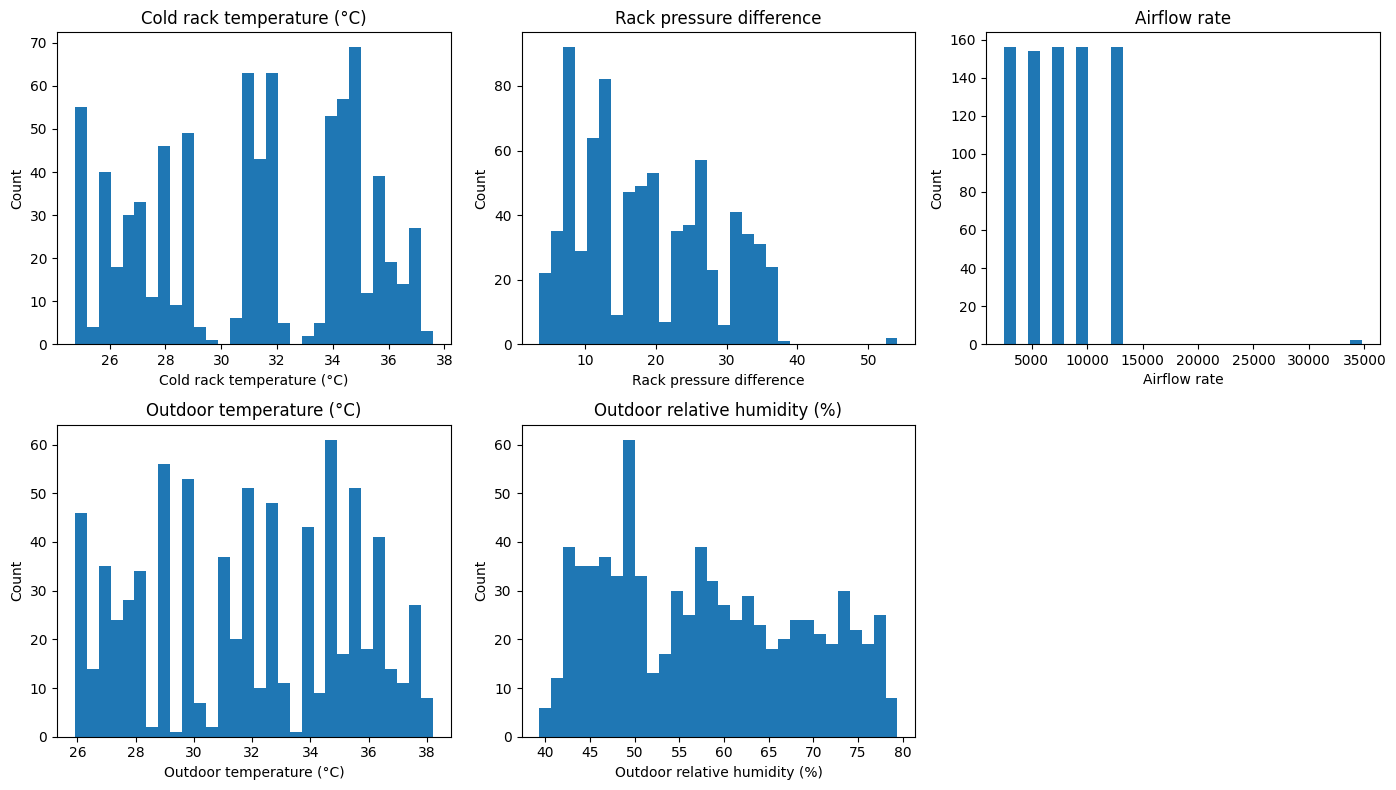

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("output/section2/wide_30min_controlled_all.csv")

def find_cols(df, include_any, exclude_any=None):
    """
    include_any: list[str] -> at least one must appear in column name (case-insensitive)
    exclude_any: list[str] -> none may appear
    """
    include_any = [s.lower() for s in include_any]
    exclude_any = [s.lower() for s in (exclude_any or [])]

    cols = []
    for c in df.columns:
        cl = c.lower()
        if any(k in cl for k in include_any) and not any(x in cl for x in exclude_any):
            cols.append(c)
    return cols

def avg_from_first_matching_group(df, groups, name):
    """
    groups: list[dict] where each dict has include_any/exclude_any
    Picks first group that yields at least 1 column.
    """
    for g in groups:
        cols = find_cols(df, g["include_any"], g.get("exclude_any"))
        if cols:
            return df[cols].mean(axis=1), cols
    raise ValueError(
        f"Could not find columns for '{name}'. "
        f"Try printing df.columns and adjusting patterns."
    )

df_plot = pd.DataFrame(index=df.index)

# --- Cold rack temperature ---
df_plot["cold_rack_temp_avg"], cold_cols = avg_from_first_matching_group(
    df,
    groups=[
        {"include_any": ["temp_cold_rack"]},
        {"include_any": ["cold_rack", "temp"]},
        {"include_any": ["temp", "cold rack"]},
    ],
    name="cold_rack_temp_avg",
)

# --- DP rack ---
df_plot["dp_rack"], dp_cols = avg_from_first_matching_group(
    df,
    groups=[
        {"include_any": ["dp_rack"]},
        {"include_any": ["dp", "rack"]},
    ],
    name="dp_rack",
)

# --- Airflow ---
df_plot["airflow_rate"], airflow_cols = avg_from_first_matching_group(
    df,
    groups=[
        {"include_any": ["airflow"]},
        {"include_any": ["air flow"]},
    ],
    name="airflow_rate",
)

# --- Outdoor temperature (try multiple naming conventions) ---
df_plot["outdoor_temp"], out_temp_cols = avg_from_first_matching_group(
    df,
    groups=[
        {"include_any": ["outdoor", "temp"], "exclude_any": ["rh", "humid"]},
        {"include_any": ["outside", "temp"], "exclude_any": ["rh", "humid"]},
        {"include_any": ["ambient", "temp"], "exclude_any": ["rh", "humid"]},
        {"include_any": ["weather", "temp"], "exclude_any": ["rh", "humid"]},
    ],
    name="outdoor_temp",
)

# --- Outdoor RH ---
df_plot["outdoor_rh"], out_rh_cols = avg_from_first_matching_group(
    df,
    groups=[
        {"include_any": ["outdoor", "rh"]},
        {"include_any": ["outside", "rh"]},
        {"include_any": ["outdoor", "humid"]},
        {"include_any": ["outside", "humid"]},
        {"include_any": ["ambient", "rh"]},
    ],
    name="outdoor_rh",
)

print("Derived variables & source columns:")
print("cold_rack_temp_avg:", cold_cols)
print("dp_rack:", dp_cols)
print("airflow_rate:", airflow_cols)
print("outdoor_temp:", out_temp_cols)
print("outdoor_rh:", out_rh_cols)

# -------- Figure 4: Histograms --------
vars_to_plot = [
    ("cold_rack_temp_avg", "Cold rack temperature (°C)"),
    ("dp_rack", "Rack pressure difference"),
    ("airflow_rate", "Airflow rate"),
    ("outdoor_temp", "Outdoor temperature (°C)"),
    ("outdoor_rh", "Outdoor relative humidity (%)"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, (col, label) in enumerate(vars_to_plot):
    axes[i].hist(df_plot[col].dropna(), bins=30)
    axes[i].set_title(label)
    axes[i].set_xlabel(label)
    axes[i].set_ylabel("Count")

fig.delaxes(axes[-1])  # remove empty slot
plt.tight_layout()
plt.show()


## DATA PREPROCESSING & FEATURE ENGINEERING

In [4]:
# ============================================================
# DATA PREPROCESSING & FEATURE ENGINEERING (ALL SETPOINTS)
#
# Input :
#   output/section2/wide_30min_controlled_all.csv
#
# Output:
#   output/section3/model_df.csv
#   output/section3/feature_list.csv
#   output/section3/plots/hist_y.png
#   output/section3/plots/y_over_time_all_setpoints.png
#   output/section3/plots/top_corr_with_y.png
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

# ----------------------------
# 0) CONFIG
# ----------------------------
IN_PATH = Path("output/section2/wide_30min_controlled_all.csv")
OUT_DIR = Path("output/section3")
PLOT_DIR = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

GROUP_COL = "supply_setpoint_label"
TARGET_COL = "y"

# 30-minute resolution → lag meanings:
# lag_1 = 30 min, lag_2 = 1 h, lag_4 = 2 h
LAGS = [1, 2, 4]
ROLL_WINDOWS = [4, 8]  # 2 h, 4 h

# Set False for leakage-free dataset (recommended for final evaluation)
INCLUDE_TARGET_LAGS = False

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 170)

# ----------------------------
# 1) LOAD DATA
# ----------------------------
df = pd.read_csv(IN_PATH)

# detect timestamp column
ts_candidates = [c for c in df.columns if re.search(r"(time|timestamp|date)", c, re.I)]
ts_col = ts_candidates[0] if ts_candidates else df.columns[0]

df[ts_col] = pd.to_datetime(df[ts_col], errors="coerce")
df = df.dropna(subset=[ts_col]).sort_values(ts_col).set_index(ts_col)

if GROUP_COL not in df.columns:
    raise KeyError(f"'{GROUP_COL}' not found in input file.")

df[GROUP_COL] = pd.to_numeric(df[GROUP_COL], errors="coerce")
df = df.dropna(subset=[GROUP_COL]).copy()
df[GROUP_COL] = df[GROUP_COL].astype(int)

setpoints = sorted(df[GROUP_COL].unique())
print("Loaded:", df.shape)
print("Setpoints included:", setpoints)

# ----------------------------
# 2) HELPERS
# ----------------------------
def find_cols(df, include_any):
    include_any = [s.lower() for s in include_any]
    return [c for c in df.columns if any(k in c.lower() for k in include_any)]

def avg_cols(df, cols):
    cols = [c for c in cols if c in df.columns]
    return df[cols].mean(axis=1) if cols else None

def add_lag_roll(df_feat, cols):
    for c in cols:
        if c not in df_feat.columns:
            continue
        for l in LAGS:
            df_feat[f"{c}__lag_{l}"] = df_feat[c].shift(l)
        for w in ROLL_WINDOWS:
            df_feat[f"{c}__roll_mean_{w}"] = df_feat[c].rolling(w).mean()
    return df_feat

def save_fig(name):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.close()

# ----------------------------
# 3) BUILD CORE FEATURES (PHYSICAL VARIABLES) — USING ALL SETPOINTS
# ----------------------------
feat = pd.DataFrame(index=df.index)
feat[GROUP_COL] = df[GROUP_COL]

# Rack temperatures
cold_cols = find_cols(df, ["temp_cold_rack"])
hot_cols  = find_cols(df, ["temp_hot_rack"])

feat["cold_rack_temp_avg"] = avg_cols(df, cold_cols)
feat["hot_rack_temp_avg"]  = avg_cols(df, hot_cols)

# Rack humidity
feat["cold_rack_rh_avg"] = avg_cols(df, find_cols(df, ["rh_cold_rack"]))
feat["hot_rack_rh_avg"]  = avg_cols(df, find_cols(df, ["rh_hot_rack"]))

# Pressure & airflow
feat["dp_rack"]      = avg_cols(df, find_cols(df, ["dp_rack"]))
feat["airflow_rate"] = avg_cols(df, find_cols(df, ["airflow-total", "airflow_total", "airflow"]))

# Outdoor conditions (robust, may include multiple columns; mean is fine here)
feat["outdoor_temp"] = avg_cols(df, find_cols(df, ["outdoor", "outside", "ambient", "temp"]))
feat["outdoor_rh"]   = avg_cols(df, find_cols(df, ["outdoor", "outside", "ambient", "rh", "humid"]))

# Energy (optional)
feat["cooling_power"] = avg_cols(df, find_cols(df, ["energy_aircon", "aircon"]))
feat["fan_power"]     = avg_cols(df, find_cols(df, ["energy_fan", "fan"]))
feat["it_power"]      = avg_cols(df, find_cols(df, ["energy_rack"]))

# Derived thermal feature
feat["delta_t"] = feat["hot_rack_temp_avg"] - feat["cold_rack_temp_avg"]

# ----------------------------
# 4) TARGET
# ----------------------------
feat[TARGET_COL] = feat["cold_rack_temp_avg"]
feat = feat.dropna(subset=[TARGET_COL]).copy()

# ----------------------------
# 5) TIME FEATURES
# ----------------------------
feat["hour"] = feat.index.hour
feat["hour_sin"] = np.sin(2 * np.pi * feat["hour"] / 24)
feat["hour_cos"] = np.cos(2 * np.pi * feat["hour"] / 24)

feat["dow"] = feat.index.dayofweek
feat["dow_sin"] = np.sin(2 * np.pi * feat["dow"] / 7)
feat["dow_cos"] = np.cos(2 * np.pi * feat["dow"] / 7)

# ----------------------------
# 6) LAG + ROLLING FEATURES (ALL SETPOINTS)
# IMPORTANT: apply shifts within each setpoint to avoid cross-regime leakage
# ----------------------------
base_cols = [c for c in [
    "delta_t", "hot_rack_temp_avg", "dp_rack", "airflow_rate",
    "outdoor_temp", "outdoor_rh", "cooling_power", "fan_power", "it_power"
] if c in feat.columns]

def add_grouped_lag_roll(df_feat, cols):
    out = df_feat.copy()
    for sp in setpoints:
        idx = out[GROUP_COL] == sp
        tmp = out.loc[idx, :].copy()
        tmp = add_lag_roll(tmp, cols)
        out.loc[idx, tmp.columns] = tmp
    return out

feat = add_grouped_lag_roll(feat, base_cols)

if INCLUDE_TARGET_LAGS:
    feat = add_grouped_lag_roll(feat, ["cold_rack_temp_avg"])

# Drop rows with NaNs introduced by lagging/rolling (per regime)
feat = feat.dropna().copy()

# ----------------------------
# 7) SAVE MODEL DATAFRAME
# ----------------------------
model_df = feat.copy()
model_df.to_csv(OUT_DIR / "model_df.csv", index=True)

feature_cols = [c for c in model_df.columns if c != TARGET_COL]
pd.DataFrame({"feature": feature_cols}).to_csv(OUT_DIR / "feature_list.csv", index=False)

print("Final model_df shape:", model_df.shape)
print("Saved:", (OUT_DIR / "model_df.csv").resolve())
print("Saved:", (OUT_DIR / "feature_list.csv").resolve())

# ----------------------------
# 8) SECTION 3 PLOTS (ALL SETPOINTS)
# ----------------------------

# 8.1 Target distribution
plt.figure(figsize=(6, 4))
plt.hist(model_df[TARGET_COL], bins=35)
plt.title("Target distribution (y = cold_rack_temp_avg)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Count")
save_fig("hist_y")

# 8.2 Target over time (ALL setpoints)
plt.figure(figsize=(12, 5))
for sp in setpoints:
    dd = model_df[model_df[GROUP_COL] == sp]
    plt.plot(dd.index, dd[TARGET_COL], label=str(sp), linewidth=1)
plt.title("Target over time for all controlled setpoints (30-min)")
plt.xlabel("Time")
plt.ylabel("Cold rack temperature (°C)")
plt.legend(ncol=7, fontsize=7)
save_fig("y_over_time_all_setpoints")

# 8.3 Top Spearman correlations with y
corr = model_df.drop(columns=[GROUP_COL]).corr(method="spearman")[TARGET_COL].sort_values()
top = pd.concat([corr.head(12), corr.tail(12)]).drop(index=[TARGET_COL], errors="ignore")

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values)
plt.title("Top Spearman correlations with target (y)")
plt.xlabel("Spearman ρ")
save_fig("top_corr_with_y")

print("Saved plots to:", PLOT_DIR.resolve())


Loaded: (780, 126)
Setpoints included: [np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37)]
Final model_df shape: (689, 65)
Saved: /Users/anastasijazubkova/Documents/TSI/ML/ml_project_2025/output/section3/model_df.csv
Saved: /Users/anastasijazubkova/Documents/TSI/ML/ml_project_2025/output/section3/feature_list.csv
Saved plots to: /Users/anastasijazubkova/Documents/TSI/ML/ml_project_2025/output/section3/plots


## MODEL TRAINING & EVALUATION

In [5]:
# ============================================================
# MODEL TRAINING & EVALUATION
# Input :
#   output/section3/model_df.csv
#
# Output:
#   output/section4/model_results_overall.csv
#   output/section4/model_results_per_regime.csv
#   output/section4/plots/*.png
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ----------------------------
# 0) CONFIG
# ----------------------------
IN_PATH = Path("output/section3/model_df.csv")
OUT_DIR = Path("output/section4")
PLOT_DIR = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

GROUP_COL = "supply_setpoint_label"
TARGET_COL = "y"

TEST_RATIO = 0.25

# ----------------------------
# 1) LOAD DATA
# ----------------------------
df = pd.read_csv(IN_PATH, parse_dates=True, index_col=0)

df = df.sort_index()
setpoints = sorted(df[GROUP_COL].unique())

print("Loaded model_df:", df.shape)
print("Setpoints:", setpoints)

# ----------------------------
# 2) TIME-AWARE TRAIN / TEST SPLIT
# ----------------------------
split_idx = int(len(df) * (1 - TEST_RATIO))

train_df = df.iloc[:split_idx]
test_df  = df.iloc[split_idx:]

X_train = train_df.drop(columns=[TARGET_COL])
y_train = train_df[TARGET_COL]

X_test = test_df.drop(columns=[TARGET_COL])
y_test = test_df[TARGET_COL]

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

# ----------------------------
# 3) BASELINE MODEL (MEAN BY SETPOINT)
# ----------------------------
baseline_means = train_df.groupby(GROUP_COL)[TARGET_COL].mean()
global_mean = train_df[TARGET_COL].mean()

def baseline_predict(df):
    return (
        df[GROUP_COL]
        .map(baseline_means)
        .fillna(global_mean)
    )

y_pred_base = baseline_predict(test_df)


# ----------------------------
# 4) MODELS
# ----------------------------
models = {
    "Baseline": None,
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
}

# ----------------------------
# 5) TRAIN + EVALUATE
# ----------------------------
results = []

def evaluate(y_true, y_pred, name):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Baseline
results.append(evaluate(y_test, y_pred_base, "Baseline"))

# Other models
for name, model in models.items():
    if model is None:
        continue

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append(evaluate(y_test, y_pred, name))

    # ----------------------------
    # Save scatter plot
    # ----------------------------
    plt.figure(figsize=(5, 5))
    plt.scatter(y_test, y_pred, alpha=0.4)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    plt.plot(lims, lims, "--")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.title(f"{name}: Actual vs Predicted")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{name.lower()}_scatter.png", dpi=150)
    plt.close()

    # ----------------------------
    # Save time-series comparison
    # ----------------------------
    plt.figure(figsize=(10, 4))
    plt.plot(y_test.index, y_test, label="Actual", linewidth=2)
    plt.plot(y_test.index, y_pred, label="Predicted", alpha=0.8)
    plt.legend()
    plt.xlabel("Time")
    plt.ylabel("Cold rack temperature (°C)")
    plt.title(f"{name}: Actual vs Predicted over time")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{name.lower()}_time_actual_vs_pred.png", dpi=150)
    plt.close()

# ----------------------------
# 6) RESULTS SUMMARY
# ----------------------------
results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "model_results_overall.csv", index=False)
print("\nOverall model performance:")
print(results_df)

# ----------------------------
# 7) PERFORMANCE BY REGIME
# ----------------------------
rows = []

for name, model in models.items():
    if name == "Baseline":
        y_pred = y_pred_base
    else:
        y_pred = model.predict(X_test)

    tmp = test_df.copy()
    tmp["y_pred"] = y_pred

    for sp in setpoints:
        d = tmp[tmp[GROUP_COL] == sp]
        if len(d) < 10:
            continue

        rows.append({
            "model": name,
            "setpoint": sp,
            "MAE": mean_absolute_error(d[TARGET_COL], d["y_pred"]),
            "RMSE": np.sqrt(mean_squared_error(d[TARGET_COL], d["y_pred"])),
            "R2": r2_score(d[TARGET_COL], d["y_pred"])
        })

per_regime_df = pd.DataFrame(rows)
per_regime_df.to_csv(OUT_DIR / "model_results_per_regime.csv", index=False)

print("\nSaved per-regime performance.")

# ----------------------------
# 8) RANDOM FOREST FEATURE IMPORTANCE
# ----------------------------
rf = models["RandomForest"]
rf.fit(X_train, y_train)

importances = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top20 = importances.head(20)
top20.to_csv(OUT_DIR / "rf_feature_importance_top20.csv")

plt.figure(figsize=(8, 6))
top20.sort_values().plot.barh()
plt.title("Random Forest – Top 20 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(PLOT_DIR / "rf_feature_importance_top20.png", dpi=150)
plt.close()

print("Saved Random Forest feature importance.")
print("Section 4 complete.")


Loaded model_df: (689, 65)
Setpoints: [np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37)]
Train shape: (516, 64)
Test shape : (173, 64)

Overall model performance:
          model           MAE          RMSE         R2
0      Baseline  5.361992e+00  5.673008e+00 -31.283639
1        Linear  9.076875e-15  1.014973e-14   1.000000
2         Ridge  8.944574e-02  1.313492e-01   0.982693
3  RandomForest  8.055562e-01  9.450300e-01   0.104126

Saved per-regime performance.
Saved Random Forest feature importance.
Section 4 complete.
